## Local Vol when the market is LV

In [1]:
%load_ext autoreload
%autoreload 1

%aimport openqai.core
%aimport openqai.core.biz_calendar
%aimport openqai.data.widb
%aimport openqai.data.widb.client
%aimport openqai.data.widb.bad
%aimport openqai.data.widb.day
%aimport quantdata.dysanos
%aimport openqai.core.backbone.backbone
%aimport openqai.benchmarks.sanos.arbfree



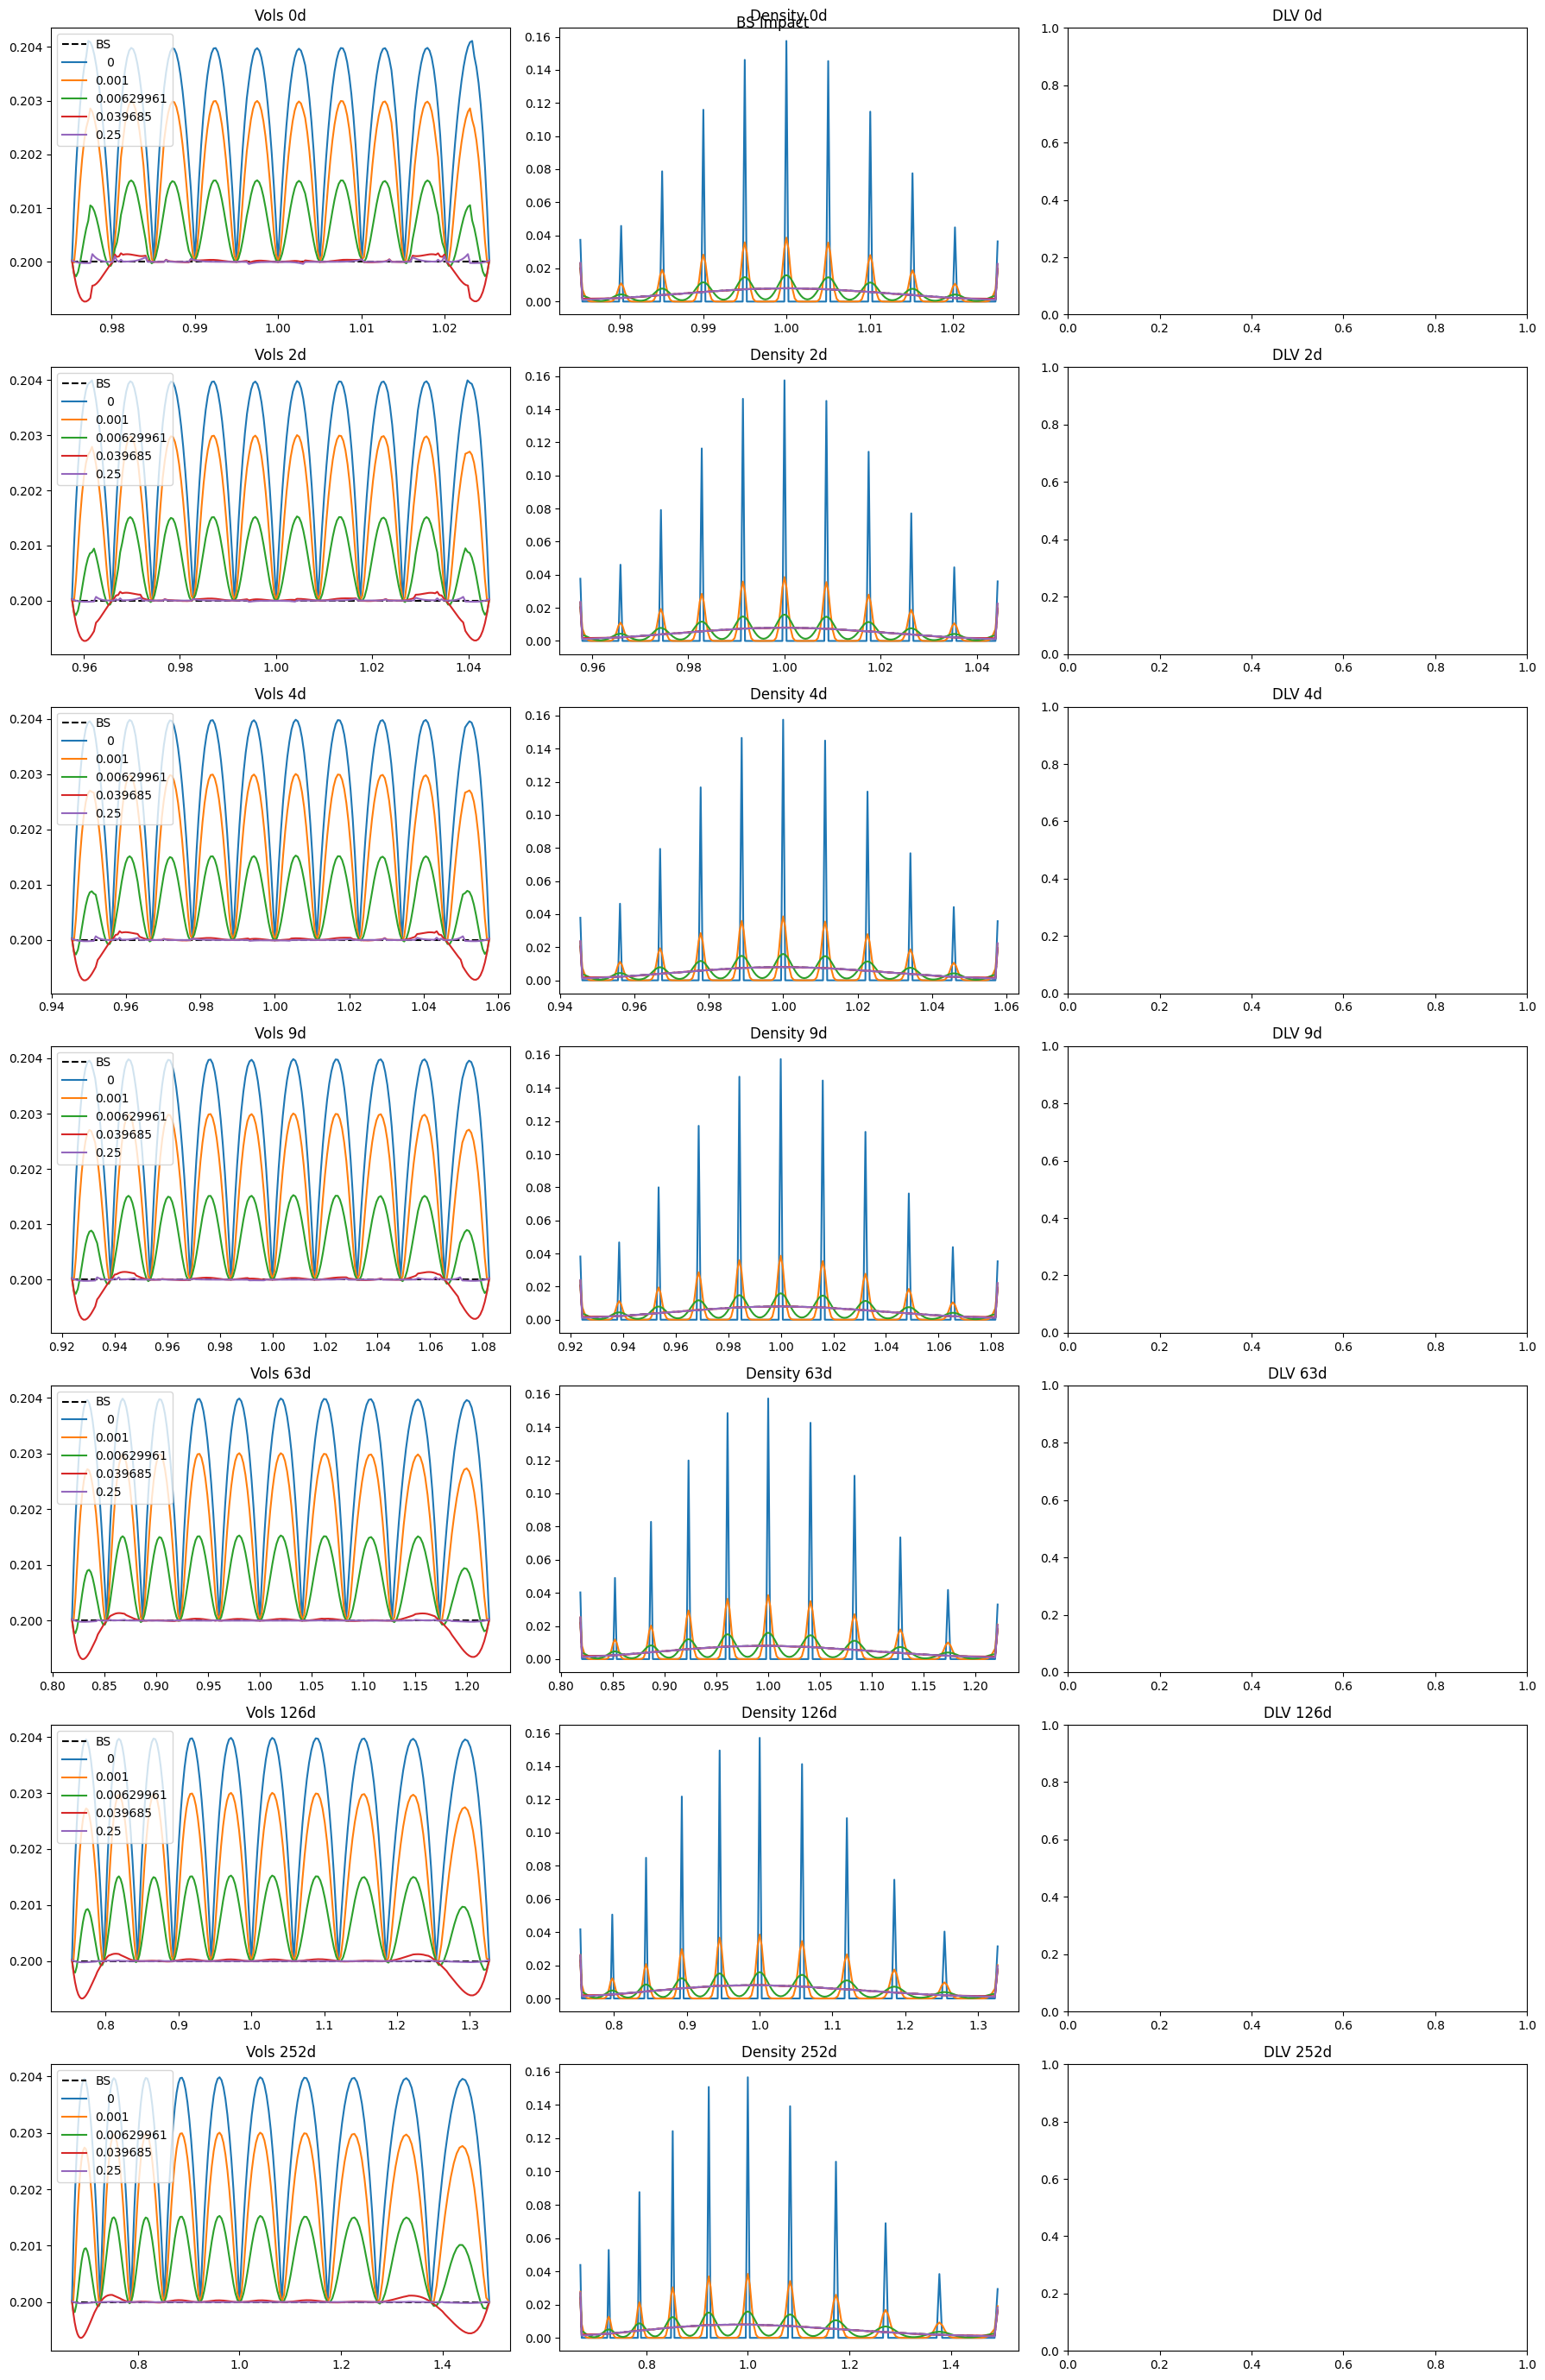

00: Fitting 0.00-smooth SANOS surface... done. This took 0.027s.
00: Fitting 0.00-smooth SANOS surface... done. This took 0.025s.
00: Fitting 0.01-smooth SANOS surface... done. This took 0.026s.
00: Fitting 0.04-smooth SANOS surface... done. This took 0.027s.
00: Fitting 0.25-smooth SANOS surface... done. This took 0.032s.


In [3]:
import numpy as np
from cdxcore.bs import bs
from cdxcore.dynaplot import figure, colors_tableau
from openqai.benchmarks.sanos.sanos import SanosFitter

def generate_market():
    vol = 0.2
    expiries = np.array([1./255, 3./255., 5./255., 10./255., 0.25, 0.5, 1. ])
    T        = len(expiries)
    N        = 11
    NN       = 201
    sqrtT    = np.sqrt( expiries )
    strikes  = np.exp( vol * np.linspace(-2,2,N)[None,:] * sqrtT[:,None] )
    mids     = bs.price( strikes, vol=vol, sqrtT=sqrtT[:,None] )
    many_strikes = np.exp( vol * np.linspace(-2,2,NN)[None,:] * sqrtT[:,None] )
    many_calls   = bs.price( many_strikes, vol=vol, sqrtT=sqrtT[:,None] ) 
    many_density = np.diff( np.diff( many_calls, prepend=1.) / np.diff( many_strikes, prepend=0.), append=0 )

    xstrikes = np.zeros((T,N+2))
    xstrikes[:,1:-1] = strikes
    xstrikes[:,0] = 0.5 * strikes[:,0]
    xstrikes[:,-1] = 1.5 * strikes[:,-1]

    strikes_  = [ strikes[t,:] for t in range(T) ]
    mids_     = [ mids[t,:] for t in range(T) ]
    xstrikes_ = [ xstrikes[t,:] for t in range(T) ]

    smoothness = np.zeros((5,)) 
    smoothness[1:] = np.exp( np.linspace( np.log(0.001), np.log(0.25), len(smoothness)-1) )

    with figure("BS Impact", row_size=4, col_size=6, columns=3 ) as fig:
        axs = [ fig.add_subplots(f"Vols {int(expiry*252)}d", f"Density {int(expiry*252)}d", f"DLV {int(expiry*252)}d") for expiry in expiries ]

        for t, (axVol, axD, axDLV) in enumerate(axs):
            axVol.plot( many_strikes[t,:], many_strikes[t,:]*0.+vol, "--", color="black", label="BS")
            axD.plot( many_strikes[t,:], many_density[t,:], "--", color="black", label="BS")
        fig.render()

        for sth in smoothness:
            fitter   = SanosFitter(smoothness=sth)
            fitted   = fitter( expiries, 
                            strikes=strikes_,
                            mids=mids_,
                            xstrikes=xstrikes_,
                            vols=vol )
            
            many_calls, many_vols = fitted( expiries=expiries[:,None], strikes=many_strikes, and_vols=True )
            many_density = np.diff( np.diff( many_calls, prepend=1.) / np.diff( many_strikes, prepend=0.), append=0 )
            dlvs = fitted.dlvsqs()

            for t, (axVol, axD, axDLV) in enumerate(axs):
                axVol.plot( many_strikes[t,:], many_vols[t,:], "-", label=f"{sth:4g}")
                axD.plot( many_strikes[t,:], many_density[t,:], "-", label=f"{sth:4g}")
#                axDLV.plot( strikes[t,:], dlvs, "-", label=f"{sth:4g}")
                axVol.legend(loc="upper left")
            fig.render()


generate_market()